
# Post-processing: plot and analyze the results

In [91]:
import meshio
import numpy as np
import glob, os

import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.colors import LogNorm
from matplotlib import mathtext
import math
from scipy import stats 
from tkinter import Tcl

#Plot Setup
font = {'size':12}
plt.rc('font', **font)
plt.rc('font', family='serif')
plt.rc('text', usetex=False)

## Measure total Energy

In [94]:
# Import snapshots
snapshot_dir = ''
files = glob.glob(snapshot_dir + "particles-*.vtu")
# Sort the snapshots
files = Tcl().call('lsort', '-dict', files)

# Simulation parameters
E_ini = 1.5622
time_step_sim = 1e-3
snapshot_rate = 10
SUN_X = 0.5
SUN_Y = 0.55

# Initialize arrays
E_dif_all = np.zeros( len(files) )
t_all = np.zeros( len(files) )

# Read snapshots and gather data
for N_snapshot, file in enumerate(files, start=0):
    
    print("N_snapshot: ", N_snapshot)
    time = N_snapshot * snapshot_rate * time_step_sim
    t_all[N_snapshot] = time
    
    print('Reading snapshot: ' + file )
    print("time of simulation = ", time)
    print("********************************************")

    mesh = meshio.read( file )
    print(mesh.point_data_to_sets)
    print("********************************************")

    # Read coordinates
    pos = mesh.point_data["x"]
    x = pos[:,0]
    y = pos[:,1]

    # Read energy
    E_tot = mesh.point_data["energyTot"][:,0]
    E_tot = np.sum(E_tot)
    E_dif = (E_tot - E_ini) / E_ini
    E_dif_all[N_snapshot] = E_dif

    print("Measure energy conservation:")
    print("Initial E = ", E_ini)
    print("Total E = ", E_tot)
    print("Relative Energy difference = ", E_dif )
    print("********************************************")

print("Done reading all snapshots. Total= ", N_snapshot )

Done reading all snapshots. Total=  100


ValueError: zero-size array to reduction operation maximum which has no identity

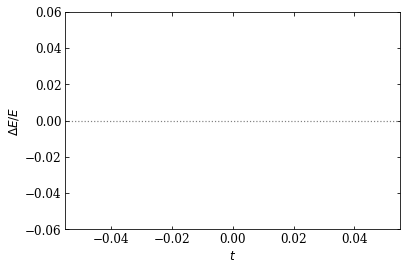

In [95]:
# Plot radial profile
fig = plt.figure(figsize=(6, 4)) 
gs = gridspec.GridSpec(1,1) 

ax0 = plt.subplot(gs[0])
plt.plot(t_all, E_dif_all, c='r', lw=0.8, zorder=1)
plt.xlabel(r'$t$')
plt.ylabel(r'$\Delta E/E$')
plt.margins(0.05, 0.1)
plt.tick_params(direction='in', top=True, right=True)
plt.axhline(0, c='gray', ls=':', lw=1.2, zorder=-49 )
plt.xlim(0, t_all.max())
plt.ylim(-0.2, 0.1 )

plt.show()
fig.savefig('energy_conservation_profile.pdf')
plt.close()

# Check energy conservation
E_tolerance = 0.15

E_min = E_dif_all.min()
E_max = E_dif_all.max()
E_mean= np.mean(E_dif_all)

assert abs(E_min) < E_tolerance, f"Energy not conserved. E_min: {E_min}"
assert abs(E_mean)< E_tolerance, f"Energy not conserved. E_mean: {E_min}"
assert abs(E_max) < E_tolerance, f"Energy not conserved. E_max: {E_max}"

# @TODO test if there is any long-term drift, e.g. of the mean.

print('Test passed!')